In [1]:
import math
import geopandas as gpd

shp = "RGI2000-v7.0-G-14_south_asia_west/RGI2000-v7.0-G-14_south_asia_west.shp"

# 
lat, lon = 36.149568, 74.856459
width_km, height_km = 40, 40
dlat = (height_km / 2) / 111.32
dlon = (width_km / 2) / (111.32 * math.cos(math.radians(lat)))
bounds = (lon - dlon, lat - dlat, lon + dlon, lat + dlat)

rgi_nagar = gpd.read_file(shp, bbox=bounds)
rgi_nagar.to_file("rgi7_nagar.gpkg", driver="GPKG")

print(f"Saved rgi7_nagar.gpkg with {len(rgi_nagar)} glaciers")
cols = [c for c in ["rgi_id", "glac_name", "area_km2", "zmin_m", "zmax_m", "term_type"] if c in rgi_nagar.columns]
print(rgi_nagar[cols].sort_values("area_km2", ascending=False).head(10).to_string(index=False))

Saved rgi7_nagar.gpkg with 220 glaciers
                 rgi_id        glac_name   area_km2    zmin_m    zmax_m  term_type
RGI2000-v7.0-G-14-21670   Hispar Glacier 449.991520 3078.4297 7839.1130          9
RGI2000-v7.0-G-14-11166             None 285.037126 2764.0989 7216.2350          9
RGI2000-v7.0-G-14-11090    Barpu Glacier  98.211134 2839.4412 7162.4604          9
RGI2000-v7.0-G-14-21805  Gharesa Glacier  72.304325 3799.7136 7566.3633          9
RGI2000-v7.0-G-14-21955   Momhil Glacier  66.935714 2886.6584 7729.9930          9
RGI2000-v7.0-G-14-24191  Bualtar Glacier  63.675534 2313.7522 7205.1580          9
RGI2000-v7.0-G-14-11007  Minapin Glacier  51.350161 2423.4358 6954.0625          9
RGI2000-v7.0-G-14-11049  Hinacna Glacier  39.291776 2587.2637 7553.8740          9
RGI2000-v7.0-G-14-24190 Salili Glacier I  37.004855 2995.8633 6838.4920          9
RGI2000-v7.0-G-14-11292             None  33.475114 2848.7227 7112.3228          9


### The Rudolph Glacier Inventory holds outlines and relevant data on Earths Glaciers, which I am trying to use to observer individual glaciers

In [6]:
import os
from dotenv import load_dotenv, find_dotenv
from sentinelhub import SHConfig, SentinelHubSession

env_path = find_dotenv(usecwd=True)
print(".env found at:", env_path or "NOT FOUND")
load_dotenv(env_path, override=True)


CDSE_BASE_URL = "https://sh.dataspace.copernicus.eu"
CDSE_TOKEN_URL = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"

def first_env(*names):
    for n in names:
        v = os.environ.get(n)
        if v:
            return v.strip().strip('"').strip("'")
    return None

config = SHConfig()
config.sh_client_id = first_env("SH_CLIENT_ID", "CDSE_CLIENT_ID", "CLIENT_ID")
config.sh_client_secret = first_env("SH_CLIENT_SECRET", "CDSE_CLIENT_SECRET", "CLIENT_SECRET")
config.sh_base_url = CDSE_BASE_URL
config.sh_token_url = CDSE_TOKEN_URL

.env found at: /Users/aliabbas/Code/Repositories/karakoram-glacier-anomaly/.env


![Map](maps/tab.png)

Image size (px): (1451, 1314)
2018: valid 100%, clean ice/snow 42.8 km², 83% of valid pixels
2019: valid 100%, clean ice/snow 43.9 km², 85% of valid pixels
2020: valid 100%, clean ice/snow 42.7 km², 83% of valid pixels
2021: valid 100%, clean ice/snow 42.0 km², 82% of valid pixels
2022: valid 100%, clean ice/snow 42.1 km², 82% of valid pixels
2023: valid 100%, clean ice/snow 41.3 km², 80% of valid pixels
2024: valid 96%, clean ice/snow 38.2 km², 77% of valid pixels
2025: valid 100%, clean ice/snow 39.9 km², 78% of valid pixels

RGI 7.0 outline area (~2000): 51.4 km²
 year  valid_pct  ice_km2  ice_pct_of_valid
 2018      100.0     42.8              83.1
 2019      100.0     43.9              85.3
 2020      100.0     42.7              83.1
 2021      100.0     42.0              81.6
 2022      100.0     42.1              81.8
 2023      100.0     41.3              80.3
 2024       96.4     38.2              77.1
 2025      100.0     39.9              77.6


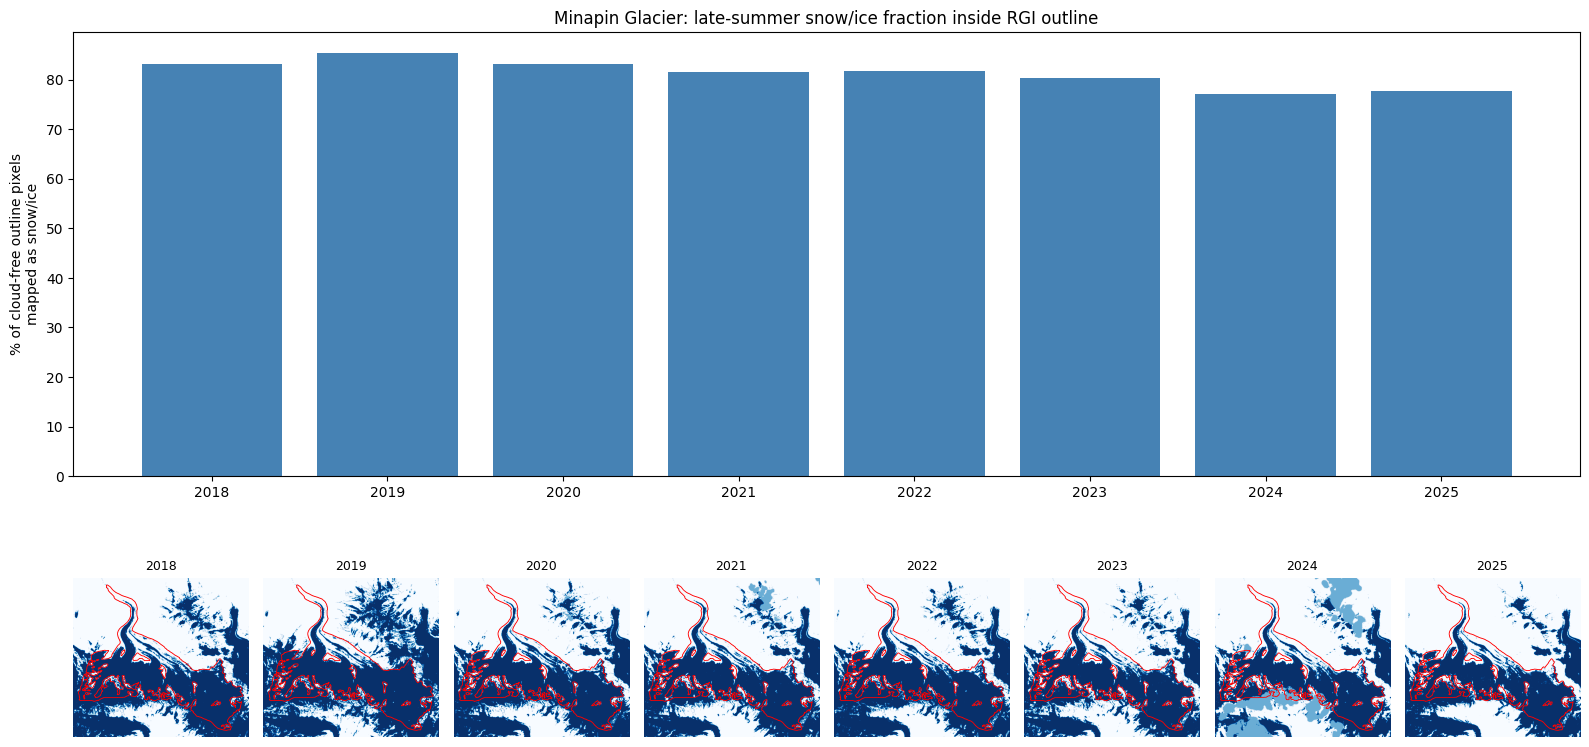

In [ ]:
import calendar
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from rasterio import features
from rasterio.transform import from_bounds
from sentinelhub import SentinelHubRequest, BBox, CRS, MimeType, DataCollection, bbox_to_dimensions

try:
    cdse_s2l2a = DataCollection["cdse_s2l2a"]
except KeyError:
    cdse_s2l2a = DataCollection.SENTINEL2_L2A.define_from("cdse_s2l2a", service_url=CDSE_BASE_URL)

rgi = gpd.read_file("rgi7_nagar.gpkg")
mina = rgi[rgi["glac_name"] == "Minapin Glacier"]
geom = mina.geometry.iloc[0]
rgi_area = float(mina["area_km2"].iloc[0])

minx, miny, maxx, maxy = geom.buffer(0.005).bounds        # ~500 m margin
bbox_m = BBox([minx, miny, maxx, maxy], crs=CRS.WGS84)
size_m = bbox_to_dimensions(bbox_m, resolution=10)
print("Image size (px):", size_m)                          # must be <= 2500 per side

# Outline rasterized onto the same pixel grid
transform = from_bounds(minx, miny, maxx, maxy, size_m[0], size_m[1])
inside = features.rasterize([(geom, 1)], out_shape=(size_m[1], size_m[0]),
                            transform=transform, fill=0).astype(bool)

lat_c = (miny + maxy) / 2
px_w = (maxx - minx) * 111320 * np.cos(np.radians(lat_c)) / size_m[0]
px_h = (maxy - miny) * 111320 / size_m[1]
px_km2 = px_w * px_h / 1e6

evalscript = """
//VERSION=3
function setup() {
    return { input: [{ bands: ["B03", "B11", "SCL", "dataMask"] }],
             output: { bands: 4, sampleType: "FLOAT32" } };
}
function evaluatePixel(s) { return [s.B03, s.B11, s.SCL, s.dataMask]; }
"""

YEARS = range(2018, 2026)
rows, ice_maps = [], {}

for y in YEARS:
    try:
        req = SentinelHubRequest(
            evalscript=evalscript,
            input_data=[SentinelHubRequest.input_data(
                data_collection=cdse_s2l2a,
                time_interval=(f"{y}-07-15", f"{y}-08-30"),
                mosaicking_order="leastCC")],
            responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
            bbox=bbox_m, size=size_m, config=config)
        d = req.get_data()[0]
    except Exception as e:
        print(f"{y}: request failed ({e})")
        continue

    g, sw, scl, dm = (d[..., i] for i in range(4))
    bad = np.isin(scl, [0, 1, 3, 8, 9, 10]) | (dm == 0)
    ndsi = (g - sw) / (g + sw + 1e-9)
    ice = (ndsi > 0.4) & (g > 0.1) & ~bad

    valid_frac = (~bad & inside).sum() / inside.sum()
    ice_km2 = (ice & inside).sum() * px_km2
    ice_frac_valid = (ice & inside).sum() / max((~bad & inside).sum(), 1)

    rows.append(dict(year=y, valid_pct=100 * valid_frac, ice_km2=ice_km2,
                     ice_pct_of_valid=100 * ice_frac_valid))
    ice_maps[y] = np.where(bad, 0.5, ice.astype(float))     # 0 = no ice, 1 = ice, 0.5 = masked
    print(f"{y}: valid {100*valid_frac:.0f}%, clean ice/snow {ice_km2:.1f} km², "
          f"{100*ice_frac_valid:.0f}% of valid pixels")

df = pd.DataFrame(rows)
df.to_csv("minapin_yearly.csv", index=False)
print(f"\nRGI 7.0 outline area (~2000): {rgi_area:.1f} km²")
print(df.round(1).to_string(index=False))

# --- Plots ---
fig = plt.figure(figsize=(16, 9))
ax = fig.add_subplot(2, 1, 1)
ax.bar(df["year"], df["ice_pct_of_valid"], color="steelblue")
ax.set_ylabel("% of cloud-free outline pixels\nmapped as snow/ice")
ax.set_title("Minapin Glacier: late-summer snow/ice fraction inside RGI outline")
ax.set_xticks(df["year"])

n = len(ice_maps)
for i, (y, m) in enumerate(ice_maps.items()):
    a = fig.add_subplot(2, n, n + i + 1)
    a.imshow(m, cmap="Blues", vmin=0, vmax=1)
    a.contour(inside, levels=[0.5], colors="red", linewidths=0.6)
    a.set_title(str(y), fontsize=9)
    a.axis("off")
plt.tight_layout()
plt.show()